# 04 · AgglomerativeClustering y GaussianMixture
    **Objetivo.** Comparar cómo se unen grupos con single/complete/average/ward
    y cómo GMM describe nubes con covarianza full o diag. Reducimos el ajuste
    para respetar memoria y tiempo, y evaluamos las predicciones en la muestra común.

**Nota de ejecución.** Celdas ejecutadas en orden con IPython dentro de `.venv`, porque nbconvert no pudo abrir los sockets del kernel en este sandbox. El usuario había verificado la versión previa con nbconvert fuera de esta restricción. Logs de esta revisión en `outputs/logs/`; auxiliares en `outputs/cache/`.

In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
sys.path.insert(0, "../../src")
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, voxel_ids, build_features
from pcseg.propagate import propagate_labels
from pcseg.metrics import cluster_summary, silhouette_sample, davies_bouldin, stability_ari
# Mostramos los PNG generados sin abrir ventanas gráficas.
plt.switch_backend("module://matplotlib_inline.backend_inline")
# Evitamos que muchos threads hagan más lento un problema pequeño.
thread_limit = threadpool_limits(limits=2)
OUT = Path('../../outputs'); FIG = OUT / 'figs'; ENT = Path('../../entregable'); ENT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'; LOGS = OUT / 'logs'
for folder in (OUT, FIG, CACHE, LOGS): folder.mkdir(exist_ok=True)
(LOGS / 'clase_labels').mkdir(exist_ok=True)
START = time.perf_counter()
SEED = 0
print('Python:', sys.executable, sys.version.split()[0])
assert Path(sys.prefix).resolve() == Path('../../.venv').resolve(), 'Ejecutar con .venv'

Python: /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


### Cómo vamos a dibujar
Usamos una función local de matplotlib: puntos de tamaño 2–2.2 y alpha=0.6. La paleta prioriza colores contrastantes y es la misma en figuras y PLY. Esto cambia la presentación, no el clustering.

In [2]:
# Reordenamos tab20: primero los tonos fuertes; misma paleta en PNG y PLY.
SEGMENT_PALETTE = (np.array(plt.get_cmap('tab20').colors)[
    np.r_[np.arange(0,20,2), np.arange(1,20,2)]] * 255).astype(np.uint8)
def segment_rgb(labels):
    return labels_to_rgb(labels, palette=SEGMENT_PALETTE)

def scatter_views(points, values, path, title, max_points=40000, seed=0):
    # Variante local: puntos visibles y alpha=0.6, sin modificar pcseg.viz.
    if len(points) > max_points:
        idx = np.random.default_rng(seed).choice(len(points), max_points, replace=False)
        points, values = points[idx], values[idx]
    colors = (segment_rgb(values) if values.ndim == 1 else values) / 255.
    fig = plt.figure(figsize=(18,6))
    for j, (axis, label) in enumerate(((1,'y'),(2,'z')), start=1):
        ax = fig.add_subplot(1,3,j)
        ax.scatter(points[:,0],points[:,axis],c=colors,s=2.2,alpha=.6,linewidths=0)
        ax.set(xlabel='x',ylabel=label,title='Superior' if j==1 else 'Lateral',aspect='equal')
    ax = fig.add_subplot(1,3,3,projection='3d')
    ax.scatter(*points.T,c=colors,s=2,alpha=.6,linewidths=0)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D')
    ax.set_box_aspect(np.maximum(np.ptp(points,axis=0),1e-9))
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

### Recuperamos la misma muestra
No volvemos a sortear puntos: cargamos los índices guardados en 01.

In [3]:
cloud = read_ply('../../data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
sample_idx = np.load(OUT / 'sample_idx.npy')
assert len(np.unique(sample_idx)) == len(sample_idx)
xyz, rgb, normals = (cloud[key][sample_idx] for key in ('xyz', 'rgb', 'normals'))
print('Muestra común:', len(xyz), 'de', len(cloud['xyz']))

Muestra común: 93903 de 1647021


### Antes de comparar: fijemos la regla
Trabajamos siempre con los índices voxel de 01. `rgb` pasa a CIE Lab dentro de
`build_features`: aquí el nombre del conjunto indica el dato de origen.
`height = z - percentil_1(z)` repite la información de z y le da más peso a la altura.

Calculamos silhouette en 1200 puntos (semilla 0) y Davies-Bouldin sin ruido.
Silhouette mayor y DB menor son deseables, pero dependen de la distancia elegida.
Por eso guardamos además `silhouette_comun` y `DB_comun`, siempre sobre las mismas
features completas estandarizadas. No hay ground truth: ninguna métrica demuestra
que los grupos sean objetos físicos. ARI compara corridas, no exactitud.
Los segundos del CSV incluyen ajuste, predicción y estabilidad, y excluyen evaluación y figuras.

In [4]:
FEATURES = {
    'xyz': {},
    'xyz+rgb': {'use_rgb': True},
    'xyz+normales': {'use_normals': True},
    'xyz+rgb+normales+height': {'use_rgb': True, 'use_normals': True, 'use_height': True},
}
def features(name, scaled=True):
    return build_features(xyz, rgb, normals, standardize=scaled, **FEATURES[name])
# Evaluación común: igual distancia y mismas filas para comparar métodos/features.
EVAL = features('xyz+rgb+normales+height')

In [5]:
NB = '04'

rows = []
def record(method, feature, scaled, params, X, labels, seconds, ari, ari_std=0., **extra):
    summary = cluster_summary(labels)
    own_sil = silhouette_sample(X, labels, n=1200, seed=0)
    own_db = davies_bouldin(X, labels)
    common_sil = silhouette_sample(EVAL, labels, n=1200, seed=0)
    common_db = davies_bouldin(EVAL, labels)
    counts = np.array(list(summary['sizes'].values()), dtype=int)
    row_id = f'{NB}_{len(rows):03d}'
    row = dict(id=row_id, metodo=method, features=feature, estandarizado=bool(scaled),
        parametros=json.dumps(params, sort_keys=True), n_fit=extra.get("n_ajuste", len(X)), n_evaluacion=len(X),
        n_clusters=summary['n_clusters'], ruido=summary['noise_frac'],
        silhouette=own_sil, DB=own_db, ARI=ari, ARI_std=ari_std,
        silhouette_comun=common_sil, DB_comun=common_db, segundos=seconds,
        min_cluster_frac=float(counts.min()/len(labels)) if len(counts) else 0.,
        max_cluster_frac=float(counts.max()/len(labels)) if len(counts) else 0., **extra)
    rows.append(row)
    np.save(LOGS / 'clase_labels' / f'{row_id}.npy', labels.astype(np.int32))
    return row

def table():
    df = pd.DataFrame(rows)
    df.to_csv(OUT / f'metricas_{NB}.csv', index=False)
    return df

def view(labels, suffix, title):
    path = FIG / f'{NB}_{suffix}.png'
    scatter_views(xyz, labels, path, title, max_points=30000, seed=0)
    display(Image(filename=str(path)))

def finish(payload):
    payload['segundos_notebook'] = time.perf_counter() - START
    (CACHE / f'clase_resumen_{NB}.json').write_text(json.dumps(payload, indent=2))
    print(payload)

### Para la jerarquía, una muestra de 3500 puntos
Unimos primero puntos o grupos cercanos. Single mira el par más cercano; complete, el más lejano; average promedia distancias; ward minimiza el aumento de WCSS. Usamos distancias completas, sin conectividad kNN, para conservar esas definiciones. Probamos K=2,4,6,8 y registramos métricas locales, además de las comunes tras propagar por vecino espacial.

In [6]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
sub_idx = np.sort(np.random.default_rng(0).choice(len(xyz), min(3500,len(xyz)), replace=False))
np.save(CACHE/'clase_jerarquico_idx.npy',sub_idx)
X = features('xyz')
for linkage in ('single','complete','average','ward'):
    for k in (2,4,6,8):
        tick = time.perf_counter()
        small_labels = AgglomerativeClustering(n_clusters=k,linkage=linkage).fit_predict(X[sub_idx])
        labels = propagate_labels(xyz[sub_idx],small_labels,xyz)
        elapsed = time.perf_counter()-tick
        ari, sd = stability_ari(lambda data, seed: labels, X, [0,1,2])
        record('agglomerative','xyz',True,{'n_clusters':k,'linkage':linkage},X,labels,
               elapsed,ari,sd, n_ajuste=len(sub_idx),
               silhouette_ajuste=silhouette_sample(X[sub_idx],small_labels,n=1200,seed=0),
               DB_ajuste=davies_bouldin(X[sub_idx],small_labels))
print('Jerarquía terminada')

Jerarquía terminada


### GMM y BIC: ajustar mejor también cuesta parámetros
Una mezcla gaussiana asigna probabilidades a componentes elípticas. Full permite correlaciones; diag solo varianzas por feature. Ajustamos 6000 puntos de las features completas, predecimos la muestra voxel y medimos estabilidad con semillas 0,1,2. BIC se calcula sobre los mismos 6000 puntos: menor es mejor dentro de esta representación, y penaliza complejidad. No lo comparamos con WCSS.

In [7]:
gmm_idx = np.sort(np.random.default_rng(0).choice(len(xyz),min(6000,len(xyz)),replace=False))
np.save(CACHE/'clase_gmm_idx.npy',gmm_idx)
X = features('xyz+rgb+normales+height')
for cov in ('full','diag'):
    for k in range(2,9):
        tick = time.perf_counter()
        runs = {s: GaussianMixture(n_components=k,covariance_type=cov,random_state=s,
                    n_init=1,max_iter=200,reg_covar=1e-5).fit(X[gmm_idx]) for s in (0,1,2)}
        predictions = {s: model.predict(X) for s,model in runs.items()}
        ari, sd = stability_ari(lambda data, seed: predictions[seed],X,[0,1,2])
        elapsed = time.perf_counter()-tick
        record('gmm','xyz+rgb+normales+height',True,
               {'n_components':k,'covariance_type':cov,'n_init':1,'max_iter':200,'reg_covar':1e-5},
               X,predictions[0],elapsed,ari,sd,n_ajuste=len(gmm_idx),
               BIC=runs[0].bic(X[gmm_idx]), converged=all(m.converged_ for m in runs.values()))
    print('GMM',cov,'listo',flush=True)
df = table()
df['seleccionado_bic'] = False
for cov in ('full','diag'):
    mask = (df.metodo=='gmm') & df.parametros.str.contains(f'"covariance_type": "{cov}"')
    df.loc[df.loc[mask,'BIC'].idxmin(),'seleccionado_bic'] = True
df.to_csv(OUT/'metricas_04.csv',index=False)
display(df[['metodo','parametros','silhouette','DB','silhouette_comun','ARI','BIC','seleccionado_bic']])

GMM full listo


GMM diag listo


,metodo,parametros,silhouette,DB,silhouette_comun,ARI,BIC,seleccionado_bic
0,agglomerative,"{""linkage"": ""single"", ""n_clusters"": 2}",NaN,0.609535,NaN,1.000000,NaN,False
1,agglomerative,"{""linkage"": ""single"", ""n_clusters"": 4}",0.141460,0.796165,0.030329,1.000000,NaN,False
2,agglomerative,"{""linkage"": ""single"", ""n_clusters"": 6}",0.141460,0.952408,0.030329,1.000000,NaN,False
3,agglomerative,"{""linkage"": ""single"", ""n_clusters"": 8}",-0.156270,1.083596,-0.087281,1.000000,NaN,False
4,agglomerative,"{""linkage"": ""complete"", ""n_clusters"": 2}",0.332378,1.143230,0.246493,1.000000,NaN,False
5,agglomerative,"{""linkage"": ""complete"", ""n_clusters"": 4}",0.346517,0.928498,0.159307,1.000000,NaN,False
6,agglomerative,"{""linkage"": ""complete"", ""n_clusters"": 6}",0.277532,1.171373,0.112747,1.000000,NaN,False
7,agglomerative,"{""linkage"": ""complete"", ""n_clusters"": 8}",0.249157,1.276881,0.045292,1.000000,NaN,False
8,agglomerative,"{""linkage"": ""average"", ""n_clusters"": 2}",0.352914,1.139140,0.254747,1.000000,NaN,False
9,agglomerative,"{""linkage"": ""average"", ""n_clusters"": 4}",0.343638,0.999623,0.173176,1.000000,NaN,False


### Contrastemos los criterios
La jerarquía es determinista para estos puntos: ARI=1 entre semillas no mide sensibilidad al submuestreo. Para GMM señalamos el mínimo BIC de cada covarianza; silhouette y DB evalúan la partición dura, que no es el objetivo de máxima likelihood de GMM.

,parametros,BIC,silhouette,DB,ARI
22,"{""covariance_type"": ""full"", ""max_iter"": 200, ""...",31491.923827,0.066215,2.793821,0.494698


,parametros,BIC,silhouette,DB,ARI
29,"{""covariance_type"": ""diag"", ""max_iter"": 200, ""...",85726.312787,0.059833,3.929238,0.791167


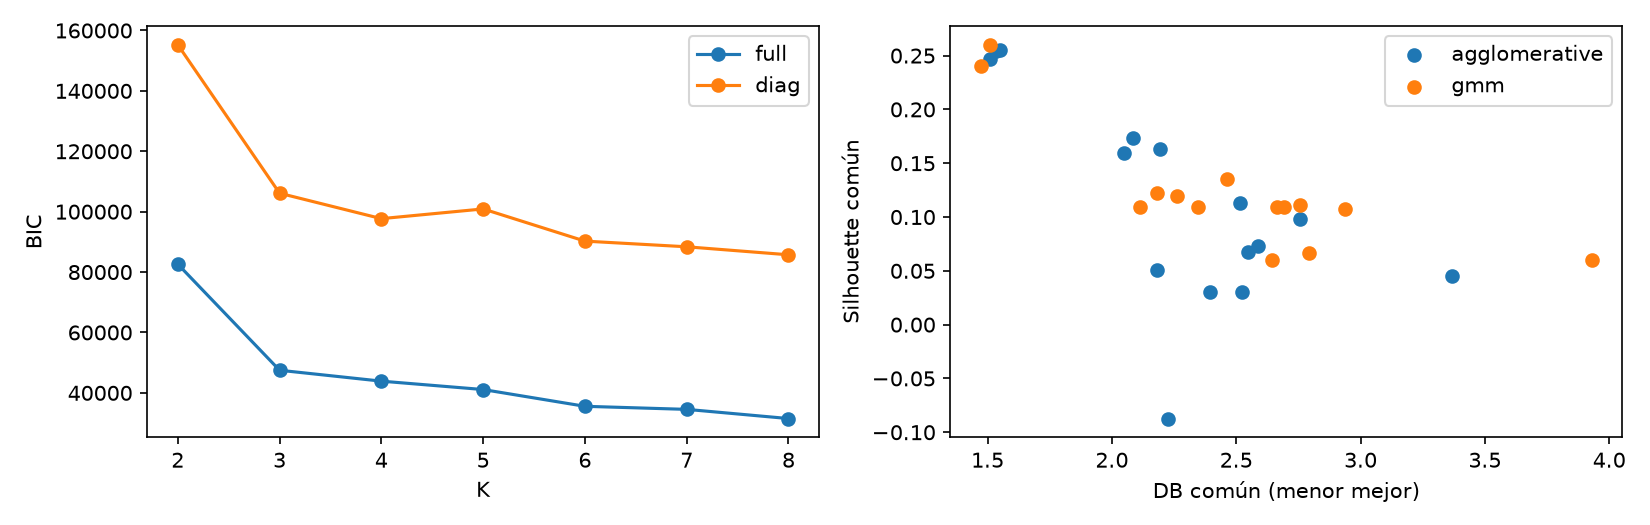

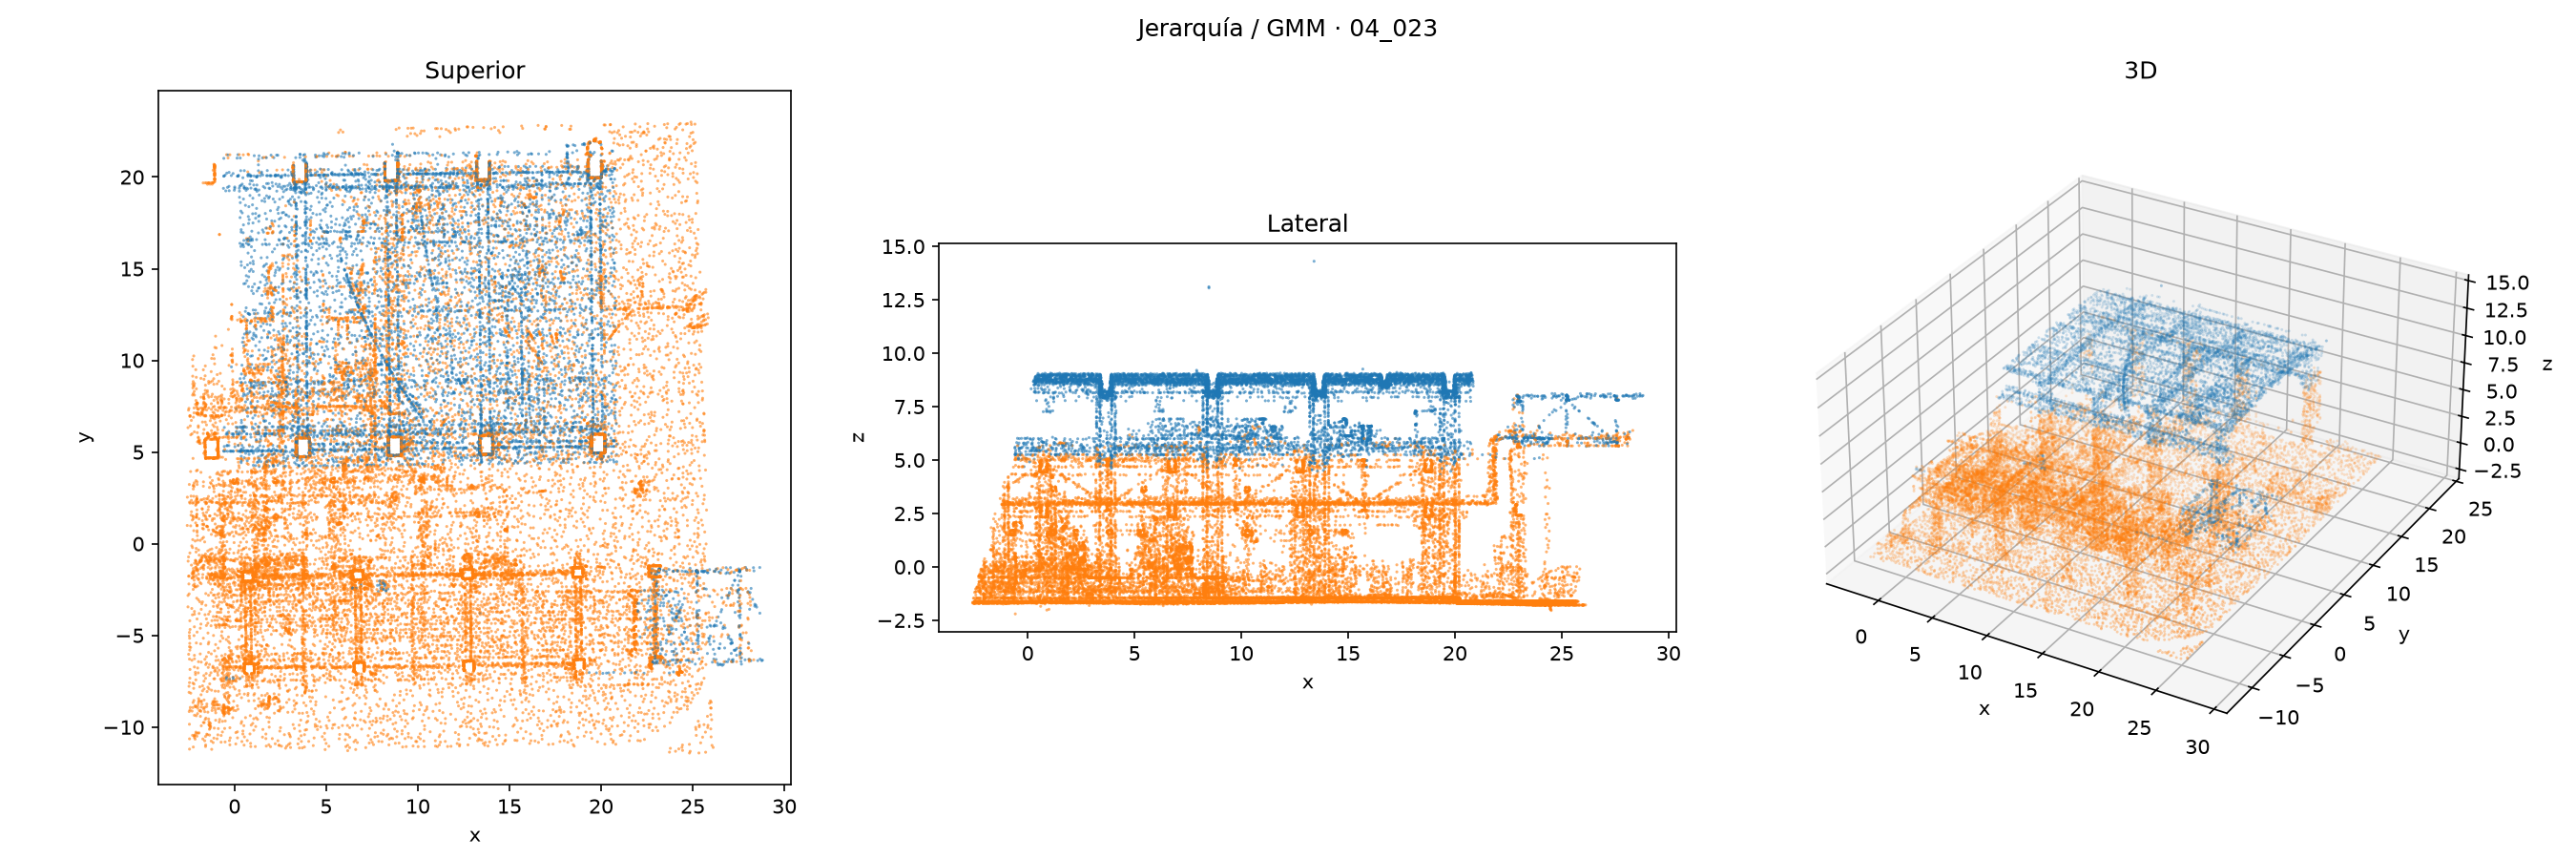

{'mejor': {'id': '04_023', 'metodo': 'gmm', 'features': 'xyz+rgb+normales+height', 'estandarizado': True, 'parametros': '{"covariance_type": "diag", "max_iter": 200, "n_components": 2, "n_init": 1, "reg_covar": 1e-05}', 'n_fit': 6000, 'n_evaluacion': 93903, 'n_clusters': 2, 'ruido': 0.0, 'silhouette': 0.2600599158924277, 'DB': 1.511489961068808, 'ARI': 1.0, 'ARI_std': 0.0, 'silhouette_comun': 0.2600599158924277, 'DB_comun': 1.511489961068808, 'segundos': 0.04890668799998821, 'min_cluster_frac': 0.2706942270215009, 'max_cluster_frac': 0.7293057729784991, 'n_ajuste': 6000, 'silhouette_ajuste': nan, 'DB_ajuste': nan, 'BIC': 155274.4245257897, 'converged': True, 'seleccionado_bic': False}, 'bic_mejor': {'id': '04_022', 'metodo': 'gmm', 'features': 'xyz+rgb+normales+height', 'estandarizado': True, 'parametros': '{"covariance_type": "full", "max_iter": 200, "n_components": 8, "n_init": 1, "reg_covar": 1e-05}', 'n_fit': 6000, 'n_evaluacion': 93903, 'n_clusters': 8, 'ruido': 0.0, 'silhouette':

In [8]:
gmm = df[df.metodo=='gmm']
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
for cov in ('full','diag'):
    p = gmm[[json.loads(s)['covariance_type']==cov for s in gmm.parametros]]
    ax[0].plot([json.loads(s)['n_components'] for s in p.parametros],p.BIC,'o-',label=cov)
    display(p.loc[[p.BIC.idxmin()],['parametros','BIC','silhouette','DB','ARI']])
ax[0].set(xlabel='K',ylabel='BIC'); ax[0].legend()
for method in ('agglomerative','gmm'):
    p=df[df.metodo==method]
    ax[1].scatter(p.DB_comun,p.silhouette_comun,label=method)
ax[1].set(xlabel='DB común (menor mejor)',ylabel='Silhouette común'); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG/'04_comparacion.png',dpi=150); display(Image(filename=str(FIG / '04_comparacion.png'))); plt.close(fig)
best = df.sort_values('silhouette_comun',ascending=False).iloc[0]
view(np.load(LOGS/'clase_labels'/f'{best.id}.npy'),'mejor',f'Jerarquía / GMM · {best.id}')
finish({'mejor':best.to_dict(),'bic_mejor':gmm.loc[gmm.BIC.idxmin()].to_dict(),
        'configuraciones':len(df),'gmm_no_convergentes':int((~gmm.converged.astype(bool)).sum())})

## Qué aprendimos / qué falló

Comparamos 30 configuraciones. El mayor silhouette común de este notebook fue 04_023 (gmm): silhouette común 0.260, DB común 1.511 y ARI 1.0000. El menor BIC de GMM fue 31491.9 con {"covariance_type": "full", "max_iter": 200, "n_components": 8, "n_init": 1, "reg_covar": 1e-05}; su silhouette común fue 0.066. Hubo 0 configuraciones de GMM sin convergencia en alguna semilla. BIC eligió K=8 para full y diag, el borde de la grilla 2–8; no sabemos si seguiría bajando fuera de ella. En 06 aplicamos el nuevo filtro de detalle y balance a todas las configuraciones; BIC queda como diagnóstico de GMM. La jerarquía se ajustó en 3500 puntos y GMM en 6000: las métricas comunes incluyen la extensión a la muestra voxel. Un ARI determinista de 1 no mide sensibilidad a esas submuestras.